## Step 1: Setup
Imports, seed, device, and a quick look at the dataset folders.

In [1]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)
print("device:", device)
if device.type == "cuda":
    print("gpu:", torch.cuda.get_device_name(0))


def show_tree(path, depth=0, max_depth=4, max_dirs=5):
    items = sorted(os.listdir(path))
    dirs = [i for i in items if os.path.isdir(os.path.join(path, i))]
    imgs = [i for i in items if i.lower().endswith((".jpg", ".jpeg", ".png"))]
    print("  " * depth + os.path.basename(path), f"({len(dirs)} folders, {len(imgs)} images)")
    if depth < max_depth:
        for d in dirs[:max_dirs]:
            show_tree(os.path.join(path, d), depth + 1, max_depth, max_dirs)


show_tree("/kaggle/input/datasets/mdsifatullahsheikh/d1-clean")

torch: 2.11.0+cu130
device: cuda
gpu: Tesla T4
d1-clean (3 folders, 0 images)
  test (60 folders, 0 images)
    00_Golden-Delicious (0 folders, 45 images)
    01_Granny-Smith (0 folders, 58 images)
    02_Pink-Lady (0 folders, 59 images)
    03_Royal-Gala (0 folders, 64 images)
    04_Avocado (0 folders, 40 images)
  train (60 folders, 0 images)
    00_Golden-Delicious (0 folders, 45 images)
    01_Granny-Smith (0 folders, 59 images)
    02_Pink-Lady (0 folders, 59 images)
    03_Royal-Gala (0 folders, 65 images)
    04_Avocado (0 folders, 41 images)
  val (60 folders, 0 images)
    00_Golden-Delicious (0 folders, 6 images)
    01_Granny-Smith (0 folders, 6 images)
    02_Pink-Lady (0 folders, 5 images)
    03_Royal-Gala (0 folders, 5 images)
    04_Avocado (0 folders, 5 images)


## Step 2: Data loaders
128x128 images. Augmentation on train only. Val and test are just resized and normalized.

In [2]:
import glob

DATA_DIR = glob.glob("/kaggle/input/**/d1-clean", recursive=True)[0]

IMG_SIZE = 224
BATCH_SIZE = 32
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.1),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_tf)
val_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), transform=eval_tf)
test_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_tf)

assert train_ds.classes == val_ds.classes == test_ds.classes
class_names = train_ds.classes
NUM_CLASSES = len(class_names)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

images, labels = next(iter(train_loader))
print("classes:", NUM_CLASSES)
print("train / val / test:", len(train_ds), len(val_ds), len(test_ds))
print("batch:", images.shape)

classes: 60
train / val / test: 1996 296 1889
batch: torch.Size([32, 3, 224, 224])


## Step 3: Simple CNN
4 conv blocks (32, 64, 128, 256 channels) with BatchNorm, then global average pooling, dropout and one linear layer.

In [3]:
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            conv_block(256, 512),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


model = SimpleCNN(NUM_CLASSES).to(device)
n_params = sum(p.numel() for p in model.parameters())
print("parameters:", f"{n_params:,}")
print("output shape:", model(images.to(device)).shape)

parameters: 4,744,988
output shape: torch.Size([32, 60])


## Step 4: Training
AdamW with weight decay, label smoothing, OneCycle learning rate, mixed precision. The best val accuracy checkpoint is saved.

In [4]:
EPOCHS = 100
MAX_LR = 3e-3
WEIGHT_DECAY = 5e-2
CUTMIX_PROB = 0.3

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=len(train_loader)
)
scaler = torch.amp.GradScaler("cuda")


def cutmix(x, y):
    lam = np.random.beta(1.0, 1.0)
    idx = torch.randperm(x.size(0), device=x.device)
    h, w = x.shape[2], x.shape[3]
    cut = np.sqrt(1 - lam)
    ch, cw = int(h * cut), int(w * cut)
    cy, cx = np.random.randint(h), np.random.randint(w)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, h)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, w)
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (h * w)
    return x, y, y[idx], lam


def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            use_cutmix = train and np.random.rand() < CUTMIX_PROB
            if use_cutmix:
                x, y_a, y_b, lam = cutmix(x, y)
            with torch.autocast(device_type="cuda"):
                out = model(x)
                if use_cutmix:
                    loss = lam * criterion(out, y_a) + (1 - lam) * criterion(out, y_b)
                else:
                    loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), "best_cnn_v3.pth")
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:03d} | train loss {tr_loss:.3f} accuracy {tr_acc:.3f} | validation loss {va_loss:.3f} accuracy {va_acc:.3f}")

train_time = time.time() - start
print(f"\nbest val acc: {best_val_acc:.3f}")
print(f"training time: {train_time/60:.1f} min")

epoch 001 | train loss 3.689 accuracy 0.108 | validation loss 3.367 accuracy 0.118
epoch 005 | train loss 2.982 accuracy 0.274 | validation loss 2.840 accuracy 0.277
epoch 010 | train loss 2.710 accuracy 0.348 | validation loss 2.831 accuracy 0.294
epoch 015 | train loss 2.513 accuracy 0.436 | validation loss 3.679 accuracy 0.247
epoch 020 | train loss 2.432 accuracy 0.477 | validation loss 2.753 accuracy 0.345
epoch 025 | train loss 2.337 accuracy 0.494 | validation loss 2.161 accuracy 0.456
epoch 030 | train loss 2.033 accuracy 0.609 | validation loss 2.499 accuracy 0.439
epoch 035 | train loss 1.962 accuracy 0.655 | validation loss 2.137 accuracy 0.574
epoch 040 | train loss 1.915 accuracy 0.674 | validation loss 2.591 accuracy 0.405
epoch 045 | train loss 1.777 accuracy 0.691 | validation loss 2.208 accuracy 0.520
epoch 050 | train loss 1.610 accuracy 0.774 | validation loss 2.154 accuracy 0.524
epoch 055 | train loss 1.648 accuracy 0.751 | validation loss 2.055 accuracy 0.608
epoc

## Step 5: Curves and clean accuracy
Loads the best checkpoint and measures train, val and test accuracy on un-augmented images.

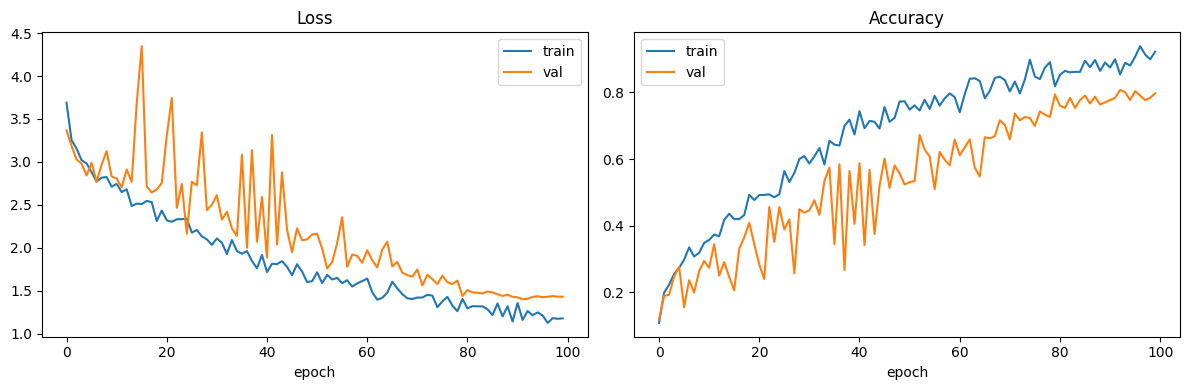

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig("curves_v3.png", dpi=150)
plt.show()



In [11]:
train_clean_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=eval_tf)
train_clean_loader = DataLoader(train_clean_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

model.load_state_dict(torch.load("best_cnn_v3.pth"))
model.eval()


def evaluate(loader):
    preds, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            preds.append(out.argmax(1).cpu())
            targets.append(y)
    preds, targets = torch.cat(preds), torch.cat(targets)
    return (preds == targets).float().mean().item(), preds, targets


train_acc, _, _ = evaluate(train_clean_loader)
val_acc, _, _ = evaluate(val_loader)
test_acc, _, _ = evaluate(test_loader)

print(f"train acc: {train_acc:.3f}")
print(f"val acc:   {val_acc:.3f}")
print(f"test acc:  {test_acc:.3f}")

train acc: 1.000
val acc:   0.807
test acc:  0.746


## Step 6: Final evaluation
Test accuracy, macro F1, per-class precision/recall/F1 and the confusion matrix.

test accuracy: 0.7464
test macro F1: 0.7525
                                           precision  recall     f1  support
00_Golden-Delicious                            0.690   0.644  0.667       45
01_Granny-Smith                                0.646   0.879  0.745       58
02_Pink-Lady                                   0.539   0.932  0.683       59
03_Royal-Gala                                  0.739   0.266  0.391       64
04_Avocado                                     0.688   0.825  0.750       40
05_Banana                                      0.909   0.682  0.779       44
06_Kiwi                                        0.750   0.667  0.706       45
07_Lemon                                       0.667   0.439  0.529       41
08_Lime                                        0.562   0.600  0.581       30
09_Mango                                       0.923   0.387  0.545       31
10_Cantaloupe                                  0.923   0.923  0.923       39
11_Galia-Melon                  

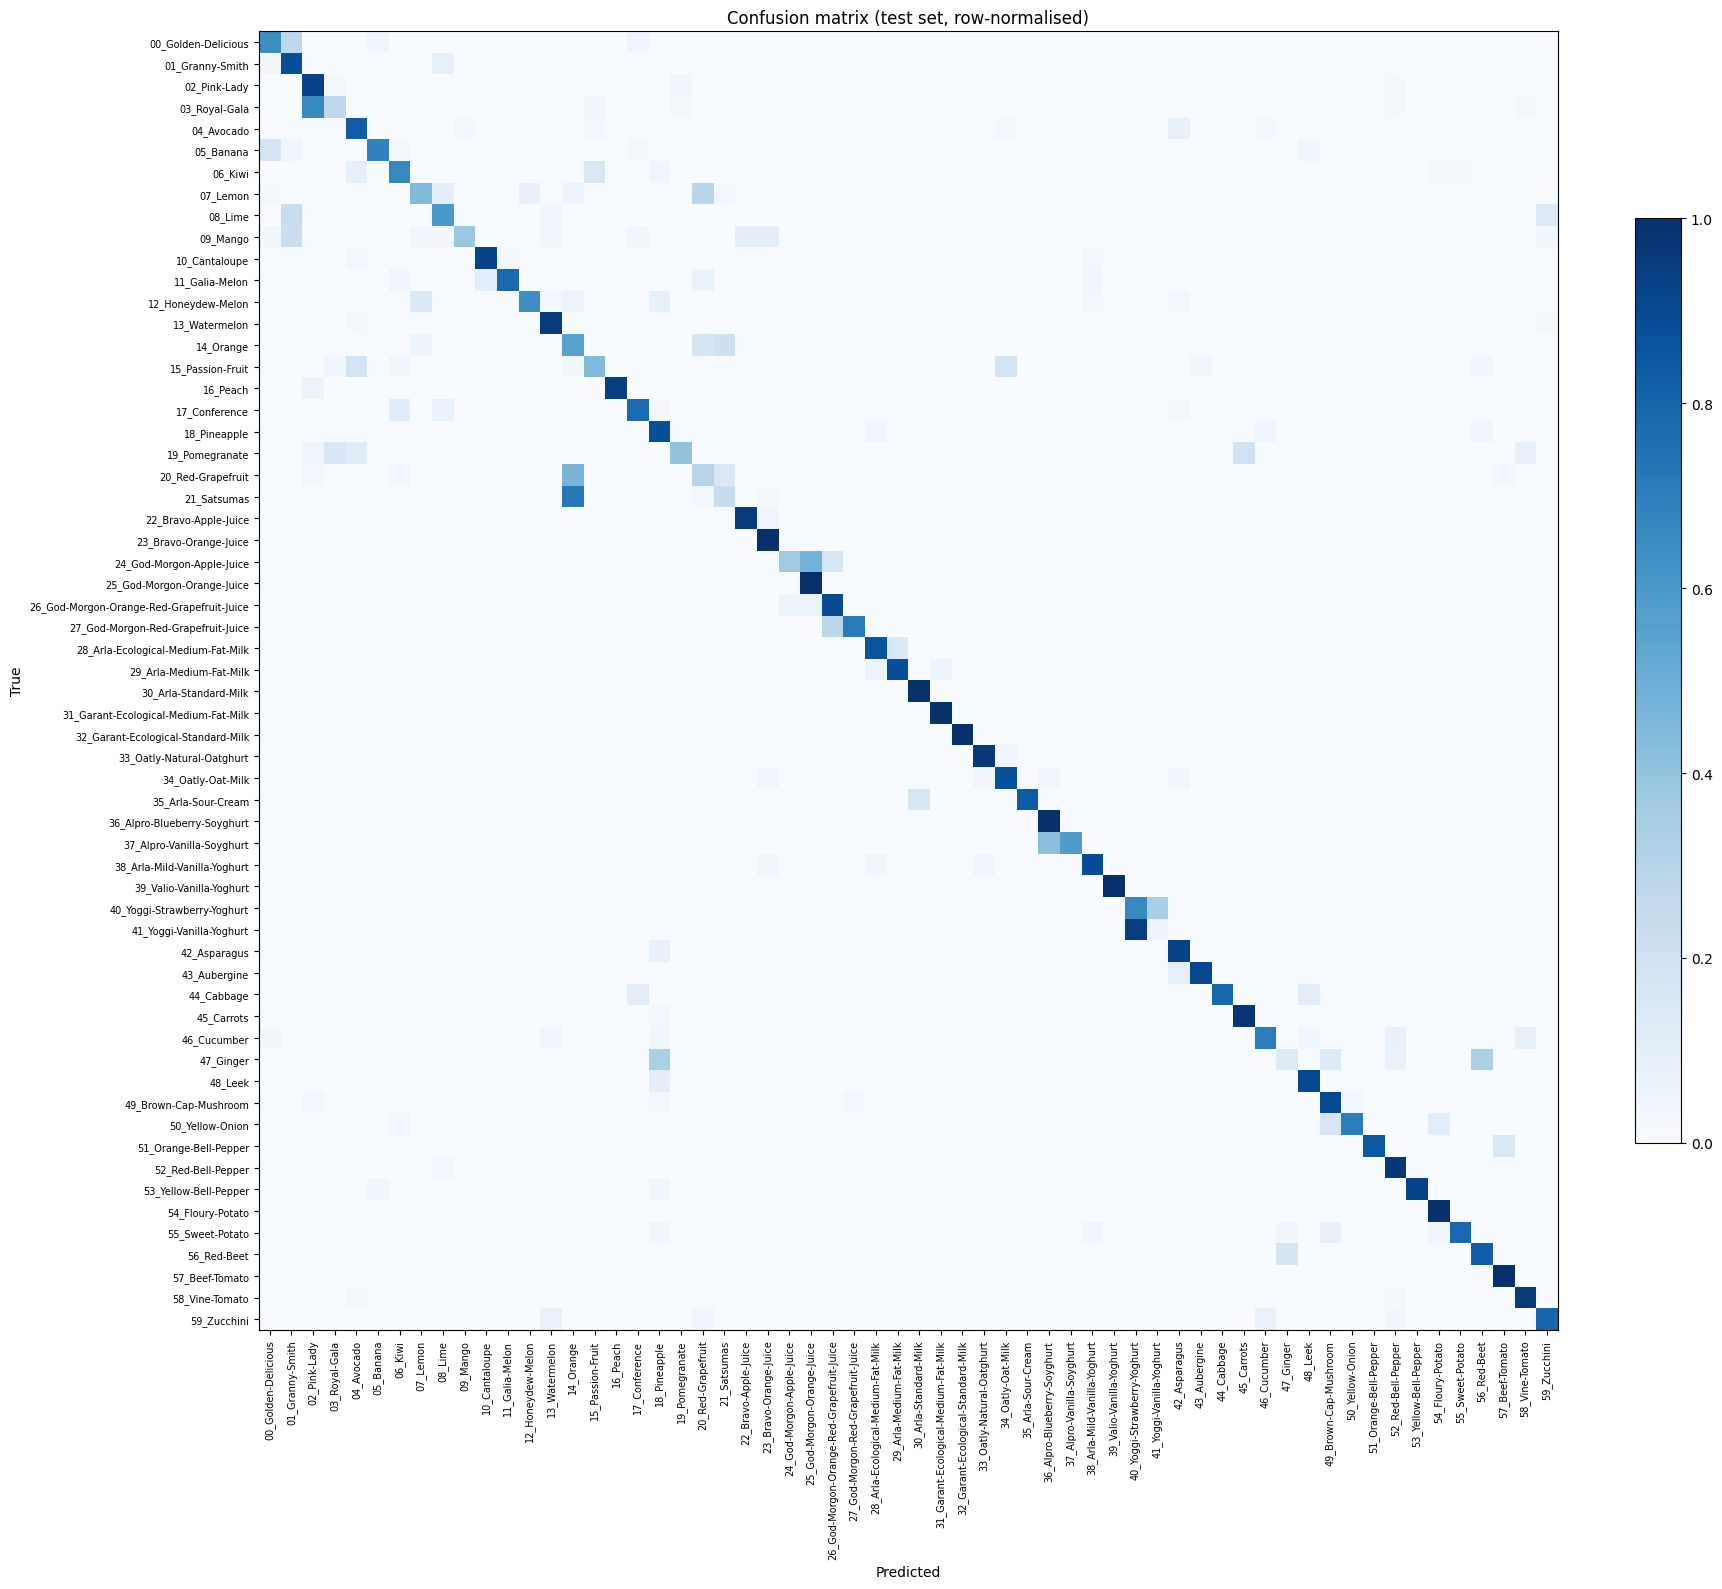


Most confused pairs (true -> predicted, count):
  21_Satsumas -> 14_Orange: 49
  03_Royal-Gala -> 02_Pink-Lady: 42
  41_Yoggi-Vanilla-Yoghurt -> 40_Yoggi-Strawberry-Yoghurt: 17
  20_Red-Grapefruit -> 14_Orange: 16
  07_Lemon -> 20_Red-Grapefruit: 12
  14_Orange -> 21_Satsumas: 12
  00_Golden-Delicious -> 01_Granny-Smith: 12
  40_Yoggi-Strawberry-Yoghurt -> 41_Yoggi-Vanilla-Yoghurt: 11
  14_Orange -> 20_Red-Grapefruit: 10
  24_God-Morgon-Apple-Juice -> 25_God-Morgon-Orange-Juice: 9


In [14]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

model.load_state_dict(torch.load("best_cnn_v3.pth"))
model.eval()

_, preds, targets = evaluate(test_loader)
y_pred, y_true = preds.numpy(), targets.numpy()

test_acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
print(f"test accuracy: {test_acc:.4f}")
print(f"test macro F1: {macro_f1:.4f}")

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.iloc[:NUM_CLASSES].round(3)
per_class.columns = ["precision", "recall", "f1", "support"]
per_class["support"] = per_class["support"].astype(int)
per_class.to_csv("per_class_report.csv")
pd.set_option("display.max_rows", None)
print(per_class)

cm = confusion_matrix(y_true, y_pred)
np.savetxt("confusion_matrix.csv", cm, fmt="%d", delimiter=",")
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticklabels(class_names, fontsize=7)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (test set, row-normalised)")
fig.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
print("\nMost confused pairs (true -> predicted, count):")
for flat in np.argsort(off_diag, axis=None)[::-1][:10]:
    i, j = divmod(flat, NUM_CLASSES)
    print(f"  {class_names[i]} -> {class_names[j]}: {off_diag[i, j]}")

In [15]:
from PIL import Image

n_params = sum(p.numel() for p in model.parameters())
size_mb = os.path.getsize("best_cnn_v3.pth") / (1024 ** 2)

cpu_model = SimpleCNN(NUM_CLASSES)
cpu_model.load_state_dict(torch.load("best_cnn_v3.pth", map_location="cpu"))
cpu_model.eval()

sample_path = test_ds.samples[0][0]
times = []
with torch.no_grad():
    for i in range(23):
        start = time.perf_counter()
        x = eval_tf(Image.open(sample_path).convert("RGB")).unsqueeze(0)
        torch.softmax(cpu_model(x), dim=1).argmax(1)
        if i >= 3:
            times.append((time.perf_counter() - start) * 1000)

print(f"parameters:      {n_params:,}")
print(f"model file size: {size_mb:.1f} MB  ")
print(f"median CPU time: {np.median(times):.1f} ms  ")
print(f"training time:   {train_time / 60:.1f} min")

parameters:      4,744,988
model file size: 18.1 MB  
median CPU time: 96.2 ms  
training time:   12.9 min
